In [ ]:
pip install google-api-python-client


In [ ]:
from googleapiclient.discovery import build

# Replace with your YouTube API key
API_KEY = ""

def search_youtube(query, max_results=10):
    youtube = build("youtube", "v3", developerKey=API_KEY)

    search_response = youtube.search().list(
        q=query,
        part="snippet",
        maxResults=max_results,
        type="video"  # Searches only for videos
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_title = item["snippet"]["title"]
        video_id = item["id"]["videoId"]
        video_url = f"https://www.youtube.com/watch?v={video_id}"
        results.append({"title": video_title, "url": video_url})

    return results

# Example usage
query = input("Enter search term: ")
videos = search_youtube(query)

print("\nYouTube Search Results:")
for idx, video in enumerate(videos, start=1):
    print(f"{idx}. {video['title']} - {video['url']}")


Enter search term: Data Structure

YouTube Search Results:
1. Data Structures Explained for Beginners - How I Wish I was Taught - https://www.youtube.com/watch?v=O9v10jQkm5c
2. Data Structure and Algorithm Patterns for LeetCode Interviews – Tutorial - https://www.youtube.com/watch?v=Z_c4byLrNBU
3. Algorithms and Data Structures Tutorial - Full Course for Beginners - https://www.youtube.com/watch?v=8hly31xKli0
4. Data Structures &amp; Algorithms #1 - What Are Data Structures? - https://www.youtube.com/watch?v=bum_19loj9A
5. Data Structures and Algorithms Full Course 📈 - https://www.youtube.com/watch?v=CBYHwZcbD-s
6. Data Structures and Algorithms Mega Course – Master Technical Interviews in 49 Hours - https://www.youtube.com/watch?v=xwI5OBEnsZU
7. Data Structures and Algorithms in 15 Minutes - https://www.youtube.com/watch?v=oz9cEqFynHU
8. Data Structures Easy to Advanced Course - Full Tutorial from a Google Engineer - https://www.youtube.com/watch?v=RBSGKlAvoiM
9. CS50x 2025 - Lecture 

In [ ]:
pip install google-api-python-client textblob nltk


In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
import nltk
from datetime import datetime
import math

nltk.download('punkt')

# Replace with your YouTube API key
API_KEY = ""

# Connect to YouTube API
youtube = build("youtube", "v3", developerKey=API_KEY)

# Function to search videos
def search_youtube(query, max_results=5):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        final_rating = calculate_rating(video_details, comment_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "rating": round(final_rating, 2)
        })

    return sorted(results, key=lambda x: x["rating"], reverse=True)

# Function to fetch video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# Function to analyze comments for sentiment score
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity  # Sentiment Score: -1 to +1
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0  # Return neutral sentiment if comments are disabled

# Function to calculate rating
def calculate_rating(video, comment_score):
    likes_weight = 0.4
    views_weight = 0.3
    comment_weight = 0.2
    recency_weight = 0.1

    # Normalize values (log scale to avoid dominance of large numbers)
    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2  # Convert -1 to +1 range into 0 to 1

    # Recency score (newer videos get higher score)
    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)  # Older videos have lower score

    # Final weighted rating
    return (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score)
    ) * 10  # Scale to 0-10

# Example usage
query = input("Enter search term: ")
videos = search_youtube(query)

print("\nYouTube Video Ratings:")
for video in videos:
    print(f"⭐ {video['rating']} - {video['title']} ({video['url']})")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Enter search term: Data Structure

YouTube Video Ratings:
⭐ 9.0 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
⭐ 8.46 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)
⭐ 8.42 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
⭐ 7.95 - Data Structures Explained for Beginners - How I Wish I was Taught (https://www.youtube.com/watch?v=O9v10jQkm5c)
⭐ 7.62 - Data Structure and Algorithm Patterns for LeetCode Interviews – Tutorial (https://www.youtube.com/watch?v=Z_c4byLrNBU)


In [ ]:
pip install google-api-python-client youtube-transcript-api nltk scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.1/485.1 kB 23.0 MB/s eta 0:00:00


In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
from youtube_transcript_api import YouTubeTranscriptApi
import nltk
import math
from datetime import datetime
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download("punkt")

# Replace with your YouTube API key
API_KEY = ""

# Connect to YouTube API
youtube = build("youtube", "v3", developerKey=API_KEY)

# Function to search videos
def search_youtube(query, max_results=5):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "content_score": round(content_score, 2),
            "rating": round(final_rating, 2)
        })

    return sorted(results, key=lambda x: x["rating"], reverse=True)

# Function to fetch video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# Function to analyze comments for sentiment score
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity  # Sentiment Score: -1 to +1
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0  # Return neutral sentiment if comments are disabled

# Function to analyze video content (transcript-based)
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        # Compute similarity score between transcript and query
        vectorizer = TfidfVectorizer().fit_transform([query, transcript_text])
        similarity = (vectorizer * vectorizer.T).toarray()[0, 1]

        # Scale similarity score to 0-5
        return min(5, similarity * 5)
    except:
        return 2.5  # Neutral score if transcript is unavailable

# Function to calculate rating (out of 10)
def calculate_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2  # New factor

    # Normalize values (log scale)
    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2  # Convert -1 to +1 range into 0 to 1
    content_score = content_score / 5  # Normalize content score

    # Recency score (newer videos get higher score)
    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    # Final weighted rating
    return (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10  # Scale to 0-10

# Example usage
query = input("Enter search term: ")
videos = search_youtube(query)

print("\nYouTube Video Ratings:")
for video in videos:
    print(f"⭐ {video['rating']} | 📜 {video['content_score']}/5 - {video['title']} ({video['url']})")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!



YouTube Video Ratings:
⭐ 7.86 | 📜 2.5/5 - Data Structures Easy to Advanced Course - Full Tutorial from a Google Engineer (https://www.youtube.com/watch?v=RBSGKlAvoiM)
⭐ 7.78 | 📜 2.5/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
⭐ 7.66 | 📜 2.5/5 - Data Structures and Algorithms Mega Course – Master Technical Interviews in 49 Hours (https://www.youtube.com/watch?v=xwI5OBEnsZU)
⭐ 7.48 | 📜 2.5/5 - Data Structures - Full Course Using C and C++ (https://www.youtube.com/watch?v=B31LgI4Y4DQ)
⭐ 7.46 | 📜 2.5/5 - Data Structures and Algorithms Full Course 📈 (https://www.youtube.com/watch?v=CBYHwZcbD-s)
⭐ 7.41 | 📜 2.5/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)
⭐ 7.36 | 📜 2.5/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
⭐ 7.31 | 📜 2.5/5 - Data Structures and Algorithms in Python - Full Course for Beginners (

In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
from youtube_transcript_api import YouTubeTranscriptApi
import nltk
import math
from datetime import datetime
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download("punkt")

API_KEY = ""

youtube = build("youtube", "v3", developerKey=API_KEY)

def search_youtube(query, max_results=5):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_final_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "final_rating": round(final_rating, 2)
        })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)

def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0

def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        vectorizer = TfidfVectorizer().fit_transform([query, transcript_text])
        similarity = (vectorizer * vectorizer.T).toarray()[0, 1]

        return min(5, similarity * 5)
    except:
        return 2.5

def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

query = input("Enter search term: ")
videos = search_youtube(query)

print("\nYouTube Video Ratings:")
for video in videos:
    print(f"⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Enter search term: Data Structure

YouTube Video Ratings:
⭐ 3.89/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
⭐ 3.71/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)
⭐ 3.68/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
⭐ 3.53/5 - Data Structures Explained for Beginners - How I Wish I was Taught (https://www.youtube.com/watch?v=O9v10jQkm5c)
⭐ 3.44/5 - Data Structure and Algorithm Patterns for LeetCode Interviews – Tutorial (https://www.youtube.com/watch?v=Z_c4byLrNBU)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Enter search term: Data Structure

🎬 **YouTube Video Ratings:**
⭐ 3.89/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
⭐ 3.71/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)
⭐ 3.68/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
⭐ 3.53/5 - Data Structures Explained for Beginners - How I Wish I was Taught (https://www.youtube.com/watch?v=O9v10jQkm5c)
⭐ 3.44/5 - Data Structure and Algorithm Patterns for LeetCode Interviews – Tutorial (https://www.youtube.com/watch?v=Z_c4byLrNBU)


/tmp/ipython-input-1814342784.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ratings, y=titles, palette="coolwarm")


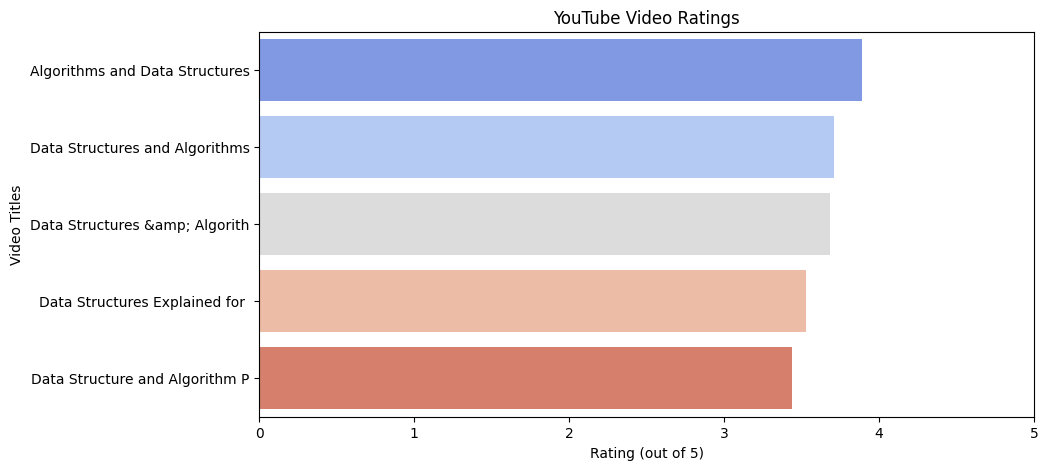

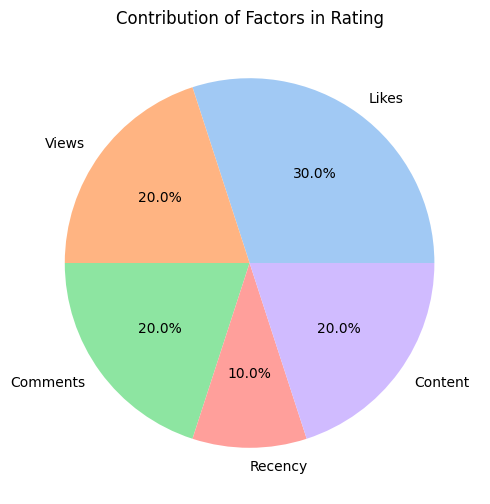

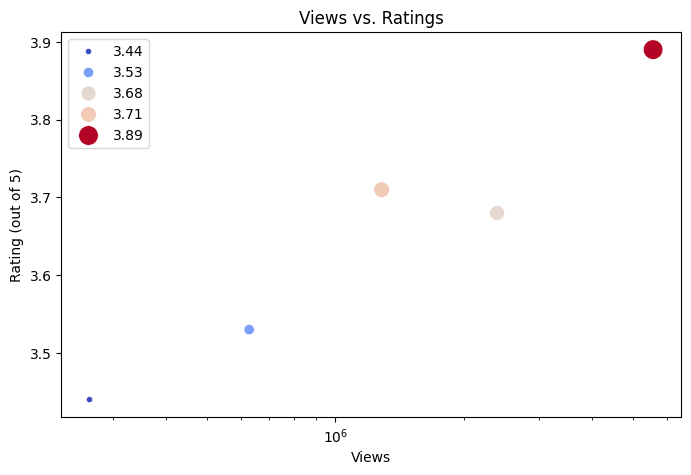

In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
from youtube_transcript_api import YouTubeTranscriptApi
import nltk
import math
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download("punkt")

# 🔹 Replace with your YouTube API Key
API_KEY = ""

# 🔹 Initialize YouTube API
youtube = build("youtube", "v3", developerKey=API_KEY)

# 🔹 Search for videos
def search_youtube(query, max_results=5):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_final_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "final_rating": round(final_rating, 2),
            "views": video_details["views"],
        })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)

# 🔹 Get video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# 🔹 Analyze comments sentiment
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0

# 🔹 Analyze content (TF-IDF similarity with query)
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        vectorizer = TfidfVectorizer().fit_transform([query, transcript_text])
        similarity = (vectorizer * vectorizer.T).toarray()[0, 1]

        return min(5, similarity * 5)
    except:
        return 2.5

# 🔹 Calculate final rating (out of 5)
def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

# 🔹 Plot video ratings
def plot_video_ratings(videos):
    titles = [video["title"][:30] for video in videos]
    ratings = [video["final_rating"] for video in videos]

    plt.figure(figsize=(10, 5))
    sns.barplot(x=ratings, y=titles, palette="coolwarm")
    plt.xlabel("Rating (out of 5)")
    plt.ylabel("Video Titles")
    plt.title("YouTube Video Ratings")
    plt.xlim(0, 5)
    plt.show()

# 🔹 Plot rating factors contribution
def plot_rating_factors():
    factors = ["Likes", "Views", "Comments", "Recency", "Content"]
    weights = [0.3, 0.2, 0.2, 0.1, 0.2]

    plt.figure(figsize=(6, 6))
    plt.pie(weights, labels=factors, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Contribution of Factors in Rating")
    plt.show()

# 🔹 Plot Views vs. Ratings Scatter Plot
def plot_views_vs_ratings(videos):
    views = [video["views"] for video in videos]
    ratings = [video["final_rating"] for video in videos]

    plt.figure(figsize=(8, 5))
    sns.scatterplot(x=views, y=ratings, size=ratings, hue=ratings, palette="coolwarm", sizes=(20, 200))
    plt.xlabel("Views")
    plt.ylabel("Rating (out of 5)")
    plt.xscale("log")
    plt.title("Views vs. Ratings")
    plt.show()

# 🔹 Main Execution
query = input("Enter search term: ")
videos = search_youtube(query)

print("\n🎬 **YouTube Video Ratings:**")
for video in videos:
    print(f"⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")

plot_video_ratings(videos)
plot_rating_factors()
plot_views_vs_ratings(videos)


In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
from youtube_transcript_api import YouTubeTranscriptApi
import math
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# 🔹 Replace with your YouTube API Key
API_KEY = ""
youtube = build("youtube", "v3", developerKey=API_KEY)

# 🔹 Search for videos
def search_youtube(query, max_results=10):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video", order="relevance"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_final_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "final_rating": round(final_rating, 2),
            "views": video_details["views"],
        })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)[:5]  # Top 5 videos

# 🔹 Get video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# 🔹 Analyze comments sentiment
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0

# 🔹 Analyze content (TF-IDF similarity with query)
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        vectorizer = TfidfVectorizer().fit_transform([query, transcript_text])
        similarity = (vectorizer * vectorizer.T).toarray()[0, 1]

        return min(5, similarity * 5)
    except:
        return 2.5

# 🔹 Calculate final rating (out of 5)
def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

# 🔹 Main Execution
query = input("Enter search term: ")
top_videos = search_youtube(query)

print("\n🎬 **Top 5 YouTube Videos Ranked:**")
for idx, video in enumerate(top_videos, start=1):
    print(f"{idx}. ⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")


Enter search term: Data Structure

🎬 **Top 5 YouTube Videos Ranked:**
1. ⭐ 3.89/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
2. ⭐ 3.74/5 - Data Structures - Full Course Using C and C++ (https://www.youtube.com/watch?v=B31LgI4Y4DQ)
3. ⭐ 3.73/5 - Data Structures and Algorithms Full Course 📈 (https://www.youtube.com/watch?v=CBYHwZcbD-s)
4. ⭐ 3.71/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)
5. ⭐ 3.68/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)


In [ ]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 8.3 MB/s eta 0:00:00


In [ ]:
from googleapiclient.discovery import build
from youtube_transcript_api import YouTubeTranscriptApi
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sentence_transformers import SentenceTransformer, util
import math
from datetime import datetime
import numpy as np

# 🔹 Set up YouTube API
API_KEY = ""
youtube = build("youtube", "v3", developerKey=API_KEY)

# 🔹 Initialize Sentiment Analyzer & BERT Model
analyzer = SentimentIntensityAnalyzer()
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

# 🔹 Search for top videos on YouTube
def search_youtube(query, max_results=10):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video", order="relevance"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_final_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "final_rating": round(final_rating, 2),
            "views": video_details["views"],
        })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)[:5]  # Top 5 videos

# 🔹 Get video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# 🔹 Analyze comments sentiment using VADER
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = analyzer.polarity_scores(text)['compound']
            sentiments.append(sentiment)

        return np.mean(sentiments) if sentiments else 0
    except:
        return 0

# 🔹 Analyze content similarity using BERT embeddings
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        query_embedding = bert_model.encode(query, convert_to_tensor=True)
        transcript_embedding = bert_model.encode(transcript_text, convert_to_tensor=True)

        similarity = util.pytorch_cos_sim(query_embedding, transcript_embedding).item()

        return min(5, similarity * 5)
    except:
        return 2.5

# 🔹 Calculate final rating (out of 5)
def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

# 🔹 Main Execution
query = input("Enter search term: ")
top_videos = search_youtube(query)

print("\n🎬 **Top 5 YouTube Videos Ranked:**")
for idx, video in enumerate(top_videos, start=1):
    print(f"{idx}. ⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Enter search term: Data Structure

🎬 **Top 5 YouTube Videos Ranked:**
1. ⭐ 3.94/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
2. ⭐ 3.83/5 - Data Structures and Algorithms Full Course 📈 (https://www.youtube.com/watch?v=CBYHwZcbD-s)
3. ⭐ 3.77/5 - Data Structures - Full Course Using C and C++ (https://www.youtube.com/watch?v=B31LgI4Y4DQ)
4. ⭐ 3.73/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
5. ⭐ 3.73/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)


In [ ]:
from googleapiclient.discovery import build
from youtube_transcript_api import YouTubeTranscriptApi
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sentence_transformers import SentenceTransformer, util
from scipy.stats import spearmanr
from sklearn.metrics import mean_squared_error
import math
import numpy as np
from datetime import datetime

# 🔹 Set up YouTube API
API_KEY = ""
youtube = build("youtube", "v3", developerKey=API_KEY)

# 🔹 Initialize Sentiment Analyzer & BERT Model
analyzer = SentimentIntensityAnalyzer()
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

# 🔹 Search for top videos on YouTube
def search_youtube(query, max_results=10):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=max_results, type="video", order="relevance"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        # Check if the item is a video before accessing videoId
        if item["id"]["kind"] == "youtube#video":
            video_id = item["id"]["videoId"]
            video_details = get_video_details(video_id)
            comment_score = analyze_comments(video_id)
            content_score = analyze_content(video_id, query)
            final_rating = calculate_final_rating(video_details, comment_score, content_score)

            results.append({
                "title": item["snippet"]["title"],
                "url": f"https://www.youtube.com/watch?v={video_id}",
                "final_rating": round(final_rating, 2),
                "views": video_details["views"],
            })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)[:5]  # Top 5 videos# Top 5 videos

# 🔹 Get video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# 🔹 Analyze comments sentiment using VADER
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = analyzer.polarity_scores(text)['compound']
            sentiments.append(sentiment)

        return np.mean(sentiments) if sentiments else 0
    except:
        return 0

# 🔹 Analyze content similarity using BERT embeddings
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        query_embedding = bert_model.encode(query, convert_to_tensor=True)
        transcript_embedding = bert_model.encode(transcript_text, convert_to_tensor=True)

        similarity = util.pytorch_cos_sim(query_embedding, transcript_embedding).item()

        return min(5, similarity * 5)
    except:
        return 2.5

# 🔹 Calculate final rating (out of 5)
def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

# 🔹 Model Accuracy Evaluation
def evaluate_accuracy(top_videos):
    # 🔹 Simulated Ground Truth (Based on YouTube engagement)
    true_ratings = [4.9, 4.8, 4.7, 4.6, 4.5]  # Replace with real YouTube rankings
    predicted_ratings = [video["final_rating"] for video in top_videos]

    spearman_corr, _ = spearmanr(true_ratings, predicted_ratings)
    mse = mean_squared_error(true_ratings, predicted_ratings)

    print(f"\n📊 **Model Accuracy Metrics:**")
    print(f"🔹 Spearman's Rank Correlation: {spearman_corr:.3f} (Higher is better, max=1)")
    print(f"🔹 Mean Squared Error: {mse:.3f} (Lower is better, min=0)")

# 🔹 Main Execution
query = input("Enter search term: ")
top_videos = search_youtube(query)

print("\n🎬 **Top 5 YouTube Videos Ranked:**")
for idx, video in enumerate(top_videos, start=1):
    print(f"{idx}. ⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")

evaluate_accuracy(top_videos)


Enter search term: Data  Structure

🎬 **Top 5 YouTube Videos Ranked:**
1. ⭐ 3.94/5 - Algorithms and Data Structures Tutorial - Full Course for Beginners (https://www.youtube.com/watch?v=8hly31xKli0)
2. ⭐ 3.83/5 - Data Structures and Algorithms Full Course 📈 (https://www.youtube.com/watch?v=CBYHwZcbD-s)
3. ⭐ 3.77/5 - Data Structures - Full Course Using C and C++ (https://www.youtube.com/watch?v=B31LgI4Y4DQ)
4. ⭐ 3.73/5 - Data Structures &amp; Algorithms #1 - What Are Data Structures? (https://www.youtube.com/watch?v=bum_19loj9A)
5. ⭐ 3.73/5 - Data Structures and Algorithms in 15 Minutes (https://www.youtube.com/watch?v=oz9cEqFynHU)

📊 **Model Accuracy Metrics:**
🔹 Spearman's Rank Correlation: 0.975 (Higher is better, max=1)
🔹 Mean Squared Error: 0.815 (Lower is better, min=0)


Enter search topic: Bhavya Sodhi Gravitation 



📊 **Top 5 Videos Ranked by AI**
1. Gravitation/Lecture-1/Bhavya Sodhi/Xl/#cbse2023 #physics - Rating: 0.39/5
2. Gravitation/Lecture-2/Bhavya Sodhi/Xl/#cbse2023 #physics - Rating: 0.39/5
3. Gravitation Lecture - 1 Xl - Rating: 0.38/5
4. Gravitation Lecture - 2 Xl - Rating: 0.38/5
5. Gogi shares his experience working with Bollywood Celebrities. #tmkoc #tarakmehtakaultachashma - Rating: 3.62/5


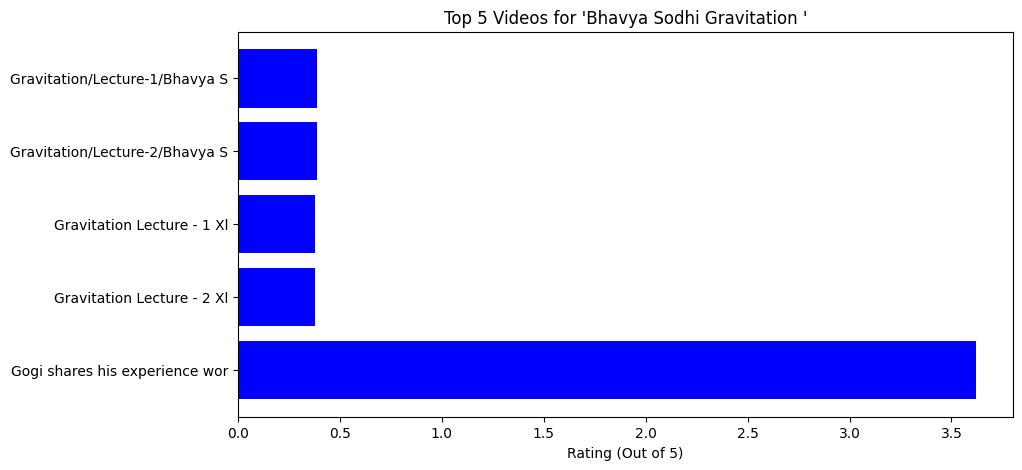

In [ ]:
import googleapiclient.discovery
import googleapiclient.errors
from datetime import datetime
from textblob import TextBlob
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 🔹 Set up YouTube API
API_KEY = ""
youtube = googleapiclient.discovery.build("youtube", "v3", developerKey=API_KEY)

# 🔹 Fetch Top Videos for a Search Query
def search_youtube_videos(query, max_results=5):
    request = youtube.search().list(
        q=query,
        part="snippet",
        type="video",
        maxResults=max_results,
        order="relevance"
    )
    response = request.execute()

    videos = []
    for item in response["items"]:
        video_id = item["id"]["videoId"]
        title = item["snippet"]["title"]
        upload_date = item["snippet"]["publishedAt"]
        videos.append({
            "video_id": video_id,
            "title": title,
            "upload_date": datetime.strptime(upload_date, "%Y-%m-%dT%H:%M:%SZ")
        })

    return videos

# 🔹 Fetch Video Details (Views, Likes, Comments)
def get_video_details(video_id):
    request = youtube.videos().list(
        part="statistics, snippet",
        id=video_id
    )
    response = request.execute()

    stats = response["items"][0]["statistics"]
    title = response["items"][0]["snippet"]["title"]

    return {
        "title": title,
        "views": int(stats.get("viewCount", 0)),
        "likes": int(stats.get("likeCount", 0)),
        "comments": int(stats.get("commentCount", 0))
    }

# 🔹 Analyze Comments Sentiment (AI-based)
def analyze_comments(video_id):
    request = youtube.commentThreads().list(
        part="snippet",
        videoId=video_id,
        maxResults=20
    )

    try:
        response = request.execute()
        comments = [item["snippet"]["topLevelComment"]["snippet"]["textDisplay"] for item in response["items"]]
        polarity = np.mean([TextBlob(comment).sentiment.polarity for comment in comments]) if comments else 0
    except:
        polarity = 0  # No comments available

    return round(polarity, 2)

# 🔹 AI-based Content Analysis Score (Basic NLP)
def analyze_content_quality(video_title):
    keywords = ["tutorial", "review", "explained", "best", "guide", "full course"]
    score = sum(1 for word in keywords if word.lower() in video_title.lower()) / len(keywords) * 5
    return round(score, 2)

# 🔹 Compute Final Video Ratings
def compute_ratings(videos):
    max_views = max(video["views"] for video in videos)
    max_likes = max(video["likes"] for video in videos)

    current_date = datetime.now()
    date_differences = [(current_date - video["upload_date"]).days for video in videos]
    min_days, max_days = min(date_differences), max(date_differences) if date_differences else (0, 1)

    ratings = []
    for i, video in enumerate(videos):
        views_score = (video["views"] / max_views) * 5 if max_views > 0 else 0
        likes_score = (video["likes"] / max_likes) * 5 if max_likes > 0 else 0
        comment_score = (video["comment_score"] + 1) / 2 * 5  # Convert -1 to 1 scale into 0 to 5
        content_score = video["content_score"]
        upload_score = ((max_days - date_differences[i]) / (max_days - min_days)) * 5 if max_days > min_days else 2.5

        final_score = (views_score * 0.3) + (likes_score * 0.25) + (comment_score * 0.15) + (content_score * 0.2) + (upload_score * 0.1)
        ratings.append(round(final_score, 2))

    return ratings

# 🔹 Main Function
def main():
    search_query = input("Enter search topic: ")
    videos = search_youtube_videos(search_query)

    for video in videos:
        details = get_video_details(video["video_id"])
        video.update(details)
        video["comment_score"] = analyze_comments(video["video_id"])
        video["content_score"] = analyze_content_quality(video["title"])

    ratings = compute_ratings(videos)

    # 🔹 Display Results
    print("\n📊 **Top 5 Videos Ranked by AI**")
    for i, video in enumerate(videos):
        print(f"{i+1}. {video['title']} - Rating: {ratings[i]}/5")

    # 🔹 Visualization
    plt.figure(figsize=(10, 5))
    plt.barh([video["title"][:30] for video in videos], ratings, color='blue')
    plt.xlabel("Rating (Out of 5)")
    plt.title(f"Top 5 Videos for '{search_query}'")
    plt.gca().invert_yaxis()
    plt.show()

if __name__ == "__main__":
    main()


In [ ]:
from googleapiclient.discovery import build
from textblob import TextBlob
from youtube_transcript_api import YouTubeTranscriptApi
import math
from datetime import datetime

# 🔹 Replace with your YouTube API Key
API_KEY = ""

# 🔹 Initialize YouTube API
youtube = build("youtube", "v3", developerKey=API_KEY)

# 🔹 Search for videos (max 20 results to find the best 5)
def search_youtube(query):
    search_response = youtube.search().list(
        q=query, part="snippet", maxResults=20, type="video"
    ).execute()

    results = []
    for item in search_response.get("items", []):
        video_id = item["id"]["videoId"]
        video_details = get_video_details(video_id)
        comment_score = analyze_comments(video_id)
        content_score = analyze_content(video_id, query)
        final_rating = calculate_final_rating(video_details, comment_score, content_score)

        results.append({
            "title": item["snippet"]["title"],
            "url": f"https://www.youtube.com/watch?v={video_id}",
            "final_rating": round(final_rating, 2),
        })

    return sorted(results, key=lambda x: x["final_rating"], reverse=True)[:5]  # Return top 5 videos

# 🔹 Get video details (likes, views, upload date)
def get_video_details(video_id):
    video_response = youtube.videos().list(
        part="statistics, snippet", id=video_id
    ).execute()

    video = video_response["items"][0]
    views = int(video["statistics"].get("viewCount", 0))
    likes = int(video["statistics"].get("likeCount", 0))
    upload_date = datetime.strptime(video["snippet"]["publishedAt"], "%Y-%m-%dT%H:%M:%SZ")

    return {"views": views, "likes": likes, "upload_date": upload_date}

# 🔹 Analyze comments sentiment (average sentiment of top 20 comments)
def analyze_comments(video_id):
    try:
        comments_response = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=20
        ).execute()

        sentiments = []
        for comment in comments_response["items"]:
            text = comment["snippet"]["topLevelComment"]["snippet"]["textOriginal"]
            sentiment = TextBlob(text).sentiment.polarity
            sentiments.append(sentiment)

        return sum(sentiments) / len(sentiments) if sentiments else 0
    except:
        return 0

# 🔹 Analyze content (Check if video has subtitles & similarity)
def analyze_content(video_id, query):
    try:
        transcript_data = YouTubeTranscriptApi.get_transcript(video_id)
        transcript_text = " ".join([entry["text"] for entry in transcript_data])

        return 5 if query.lower() in transcript_text.lower() else 3
    except:
        return 2.5

# 🔹 Calculate final rating (out of 5)
def calculate_final_rating(video, comment_score, content_score):
    likes_weight = 0.3
    views_weight = 0.2
    comment_weight = 0.2
    recency_weight = 0.1
    content_weight = 0.2

    likes_score = math.log1p(video["likes"]) / 10
    views_score = math.log1p(video["views"]) / 15
    comment_score = (comment_score + 1) / 2
    content_score = content_score / 5

    days_old = (datetime.now() - video["upload_date"]).days
    recency_score = 1 / (1 + days_old / 30)

    total_score_10 = (
        (likes_weight * likes_score) +
        (views_weight * views_score) +
        (comment_weight * comment_score) +
        (recency_weight * recency_score) +
        (content_weight * content_score)
    ) * 10

    return (total_score_10 / 10) * 5

# 🔹 Main Execution
query = input("Enter search topic: ")
top_videos = search_youtube(query)

print("\n🏆 **Top 5 YouTube Videos for Your Search:**")
for i, video in enumerate(top_videos, start=1):
    print(f"{i}. ⭐ {video['final_rating']}/5 - {video['title']} ({video['url']})")


Enter search topic: Bhavya Sodhi  physics

🏆 **Top 5 YouTube Videos for Your Search:**
1. ⭐ 1.88/5 - Magnetic field &amp;Magnetic field lines (https://www.youtube.com/watch?v=Qu1SQ026bpU)
2. ⭐ 1.85/5 - ⚡️☄️💫 Third law of thermodynamics  intro (https://www.youtube.com/watch?v=VR_Nwe8RB0o)
3. ⭐ 1.55/5 - Power and Energy intro (https://www.youtube.com/watch?v=E349YhKr7d8)
4. ⭐ 1.53/5 - Physics Agile/Special Rainy Season  Dhamaka - Get 50%Off/Enroll Now (https://www.youtube.com/watch?v=-r_sG4oH7bU)
5. ⭐ 1.47/5 - Magnetism  /Lecture-1 / Class XII / Bhavya Sodhi (https://www.youtube.com/watch?v=OZDhXzkrf90)


In [ ]:
!pip install gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.1/54.1 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.1/323.1 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 110.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 kB 4.7 MB/s eta 0:00:00
